# Step 5: Abstractive stage with LED (fine-tune + generate)

Fine-tunes `allenai/led-base-16384` to rewrite selected sentences into a fluent legal summary.

* **Training pairs:** oracle sentences (teacher forcing) -> reference summary.
* **Inference input:** the Step 3+4 selection (`led_input_text`: GNN + diffusion + MMR).
* **Optional entity-control prefix** (`entities: a ; b ; c || ...`): the most frequent legal entities of the selected sentences are prepended at training *and* inference, which nudges the generator to keep them (this sets up Step 6).
* **Tech:** `transformers` Seq2SeqTrainer, `datasets`, `accelerate`, fp16, gradient checkpointing, batch size 1 + gradient accumulation, global attention on the first token, early stopping, optional LoRA (`peft`), beam search with `no_repeat_ngram_size=3`, `length_penalty=2.0`.

**Important limit:** LED-base's *decoder* has 1,024 positions, so generated summaries cannot exceed 1,024 tokens (about 700 words). The notebook measures your reference lengths and sets `max_length` accordingly.

**Runtime: T4 GPU.** If Colab asks to restart the session after the first cell, restart and continue from cell 2. Training is checkpointed to Drive and resumes automatically; generated summaries are saved one by one, so a disconnect never costs you more than the current batch.

In [1]:
!pip -q install -U transformers datasets accelerate peft rouge-score tqdm sentencepiece
from google.colab import drive
drive.mount('/content/drive')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
Mounted at /content/drive


In [2]:
# ============ EDIT THESE (same BASE as Steps 0-4) ============
BASE        = "/content/drive/MyDrive/inabs_project"
GRAPH_DIR   = f"{BASE}/graphs"          # Step 1
EXT_DIR     = f"{BASE}/extractive"      # Steps 3+4  (selections_final.json)
OUT_DIR     = f"{BASE}/led"             # this step
SPLIT_NAMES = ["train", "validate", "test"]
# =============================================================

MODEL_NAME = "allenai/led-base-16384"

# ---- inputs / targets
MAX_INPUT_TOKENS  = 4096        # raise to 8192 only if memory allows
USE_ENTITY_PREFIX = True        # entity-control prefix (train + inference)
PREFIX_ENTITIES   = 8

# ---- training (T4 settings)
EPOCHS, PATIENCE = 6, 2         # early stopping on validation loss
LR, WEIGHT_DECAY, WARMUP = 5e-5, 0.01, 0.05
GRAD_ACCUM = 8                  # batch size is 1; effective batch = 8
LABEL_SMOOTHING = 0.1
EVAL_DOCS  = 50                 # validation documents used for the per-epoch loss
SEED = 42
USE_LORA = False                # True if you run out of GPU memory (much smaller checkpoints, ~same quality for small data)
LORA_R, LORA_ALPHA, LORA_DROPOUT, LORA_LR = 16, 32, 0.05, 2e-4
RETRAIN = False                 # False = reuse led/final_model if it exists. To retrain from scratch: set True AND delete the led/checkpoints folder (otherwise training resumes from it)

# ---- generation
NUM_BEAMS, NO_REPEAT_NGRAM, LENGTH_PENALTY = 4, 3, 2.0
GEN_BATCH = 2                   # documents per generate() call (lower to 1 if you hit out-of-memory)
GEN_SPLITS = ["test", "validate"]
N_VAL_GEN = 10                  # validation documents to generate (a sanity check; every test document is always generated)
MIN_WORDS_OK = 50               # shorter outputs fall back to the extractive summary

ALLOW_CPU = False               # leave False on Colab (training on CPU is impractical)

In [3]:
import os, re, json, math, time, gc, random, inspect, warnings
from pathlib import Path
from collections import Counter
from dataclasses import dataclass
import numpy as np, pandas as pd, torch
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")
import transformers, datasets, accelerate
from transformers import (AutoTokenizer, AutoConfig, AutoModelForSeq2SeqLM, Seq2SeqTrainer,
                          Seq2SeqTrainingArguments, EarlyStoppingCallback, set_seed)
from transformers.trainer_utils import get_last_checkpoint
from datasets import Dataset

HAS_GPU = torch.cuda.is_available()
if not HAS_GPU and not ALLOW_CPU:
    raise RuntimeError("No GPU found. In Colab: Runtime > Change runtime type > T4 GPU, then rerun.")
USE_FP16 = HAS_GPU                                   # T4 has fp16 (no bf16)
DEVICE = torch.device("cuda" if HAS_GPU else "cpu")
set_seed(SEED)
print(f"transformers {transformers.__version__} | datasets {datasets.__version__} | accelerate {accelerate.__version__} | torch {torch.__version__}")
print("device:", torch.cuda.get_device_name(0) if HAS_GPU else "CPU", "| fp16:", USE_FP16)

CKPT_DIR, FINAL_DIR = Path(OUT_DIR, "checkpoints"), Path(OUT_DIR, "final_model")
for d in ("checkpoints", "figures", "generations"): Path(OUT_DIR, d).mkdir(parents=True, exist_ok=True)

transformers 5.24.0 | datasets 5.2.0 | accelerate 1.16.0 | torch 2.14.1+cu130
device: Tesla T4 | fp16: True


## 1. Load the data: graphs (sentences, oracle labels, references, entities) and the Step 3+4 selections

In [4]:
GR = {}
for split in SPLIT_NAMES:
    for p in sorted(Path(GRAPH_DIR, split).glob("*.pt")):
        g = torch.load(p, map_location="cpu", weights_only=True); GR[(split, g["doc_id"])] = g
print({s: sum(1 for k in GR if k[0] == s) for s in SPLIT_NAMES}, "graphs")
SEL = json.load(open(Path(EXT_DIR, "selections_final.json")))["docs"]
for s in SPLIT_NAMES:
    missing = [d for d in SEL[s] if (s, d) not in GR]
    assert not missing, f"selections refer to documents without graphs: {missing[:3]}"

def norm_entity(t):                                  # same normalisation as Step 1
    t = str(t).lower().replace("&", " and ")
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]|_", " ", t)).strip()

def prefix_entities(g, idx):
    """most frequent legal entities (Step 1 graph) in the selected sentences"""
    cnt = Counter(e for j in idx for e in g["sent_entities"][j])
    return [e for e, _ in sorted(cnt.items(), key=lambda kv: (-kv[1], kv[0]))[:PREFIX_ENTITIES]]

def make_source(g, idx):
    ents = prefix_entities(g, idx) if USE_ENTITY_PREFIX else []
    head = ("entities: " + " ; ".join(ents) + " || ") if ents else ""
    return head + " ".join(g["sentences"][j] for j in idx), ents

{'train': 300, 'validate': 60, 'test': 100} graphs


## 2. Tokenizer, length statistics, and the generation length limits

In [5]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
cfg0 = AutoConfig.from_pretrained(MODEL_NAME)
DECODER_LIMIT = int(cfg0.max_decoder_position_embeddings)      # 1024 for led-base-16384
def ntok(texts): return np.array([len(x) for x in tok(list(texts), truncation=False)["input_ids"]])

train_keys = [k for k in GR if k[0] == "train"]
ref_tok = ntok([GR[k]["reference"] for k in train_keys])
MAX_TARGET = int(min(DECODER_LIMIT, np.percentile(ref_tok, 95)))
clipped = np.minimum(ref_tok, MAX_TARGET)
GEN_MAX = MAX_TARGET
GEN_MIN = int(max(20, min(0.7 * np.median(clipped), MAX_TARGET - 20)))

orc_src = [make_source(GR[k], sorted(GR[k]["oracle_idx"]))[0] for k in train_keys if GR[k]["oracle_idx"]]
inf_src = [make_source(GR[(s, d)], v["led_input_idx"])[0] for s in ("validate", "test") for d, v in SEL[s].items()]
t_orc, t_inf = ntok(orc_src), ntok(inf_src)
STATS = dict(
    reference_tokens=dict(median=int(np.median(ref_tok)), p90=int(np.percentile(ref_tok, 90)), p95=int(np.percentile(ref_tok, 95)), max=int(ref_tok.max())),
    decoder_limit=DECODER_LIMIT, max_target_tokens=MAX_TARGET, gen_min_length=GEN_MIN, gen_max_length=GEN_MAX,
    refs_longer_than_target_pct=round(float((ref_tok > MAX_TARGET).mean() * 100), 1),
    oracle_input_tokens=dict(median=int(np.median(t_orc)), p95=int(np.percentile(t_orc, 95)), over_limit_pct=round(float((t_orc > MAX_INPUT_TOKENS).mean() * 100), 1)),
    led_input_tokens=dict(median=int(np.median(t_inf)), p95=int(np.percentile(t_inf, 95)), over_limit_pct=round(float((t_inf > MAX_INPUT_TOKENS).mean() * 100), 1)),
)
json.dump(STATS, open(Path(OUT_DIR, "token_stats.json"), "w"), indent=1)
print(json.dumps(STATS, indent=1))
print(f"\nGeneration limits: max_length={GEN_MAX} tokens, min_length={GEN_MIN} tokens (about {GEN_MAX / 1.4:.0f} / {GEN_MIN / 1.4:.0f} words)")
if STATS["refs_longer_than_target_pct"] > 25:
    print(f"NOTE: {STATS['refs_longer_than_target_pct']}% of reference summaries are longer than the decoder limit; training targets are cut at a sentence boundary "
          f"and generated summaries will be shorter than your references (ROUGE recall suffers, precision does not).")
if max(STATS["oracle_input_tokens"]["over_limit_pct"], STATS["led_input_tokens"]["over_limit_pct"]) > 10:
    print("NOTE: more than 10% of inputs exceed MAX_INPUT_TOKENS and will be cut at the end. Consider MAX_INPUT_TOKENS = 8192 if memory allows.")

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (17761 > 16384). Running this sequence through the model will result in indexing errors


{
 "reference_tokens": {
  "median": 781,
  "p90": 1859,
  "p95": 2567,
  "max": 17761
 },
 "decoder_limit": 1024,
 "max_target_tokens": 1024,
 "gen_min_length": 546,
 "gen_max_length": 1024,
 "refs_longer_than_target_pct": 34.7,
 "oracle_input_tokens": {
  "median": 1067,
  "p95": 3452,
  "over_limit_pct": 4.0
 },
 "led_input_tokens": {
  "median": 1550,
  "p95": 2615,
  "over_limit_pct": 1.2
 }
}

Generation limits: max_length=1024 tokens, min_length=546 tokens (about 731 / 390 words)
NOTE: 34.7% of reference summaries are longer than the decoder limit; training targets are cut at a sentence boundary and generated summaries will be shorter than your references (ROUGE recall suffers, precision does not).


## 3. Build the datasets (`datasets` library)

In [6]:
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+")
def trim_to_tokens(text, max_tokens):
    """cut an over-long reference at a sentence boundary so the model learns clean endings"""
    if len(tok(text, truncation=False)["input_ids"]) <= max_tokens: return text
    out, used = [], 2
    for s in SENT_SPLIT.split(text):
        n = len(tok(s, add_special_tokens=False)["input_ids"]) + 1
        if used + n > max_tokens: break
        out.append(s); used += n
    return " ".join(out) if out else text

rng = random.Random(SEED)
val_keys = sorted(k for k in GR if k[0] == "validate"); eval_keys = rng.sample(val_keys, min(EVAL_DOCS, len(val_keys)))
def records(keys):
    out, skipped = [], 0
    for k in keys:
        g = GR[k]
        if not g["oracle_idx"]: skipped += 1; continue
        src, _ = make_source(g, sorted(g["oracle_idx"]))
        out.append(dict(source=src, target=trim_to_tokens(g["reference"], MAX_TARGET)))
    if skipped: print(f"  skipped {skipped} documents without oracle sentences")
    return out

def tokenize_fn(ex):
    enc = tok(ex["source"], max_length=MAX_INPUT_TOKENS, truncation=True)
    lab = tok(text_target=ex["target"], max_length=MAX_TARGET, truncation=True)
    return dict(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], labels=lab["input_ids"])

ds_train = Dataset.from_list(records(train_keys)).map(tokenize_fn, remove_columns=["source", "target"])
ds_eval  = Dataset.from_list(records(eval_keys)).map(tokenize_fn, remove_columns=["source", "target"])
print(f"train examples: {len(ds_train)} | eval examples: {len(ds_eval)} | optimizer steps per epoch: {math.ceil(len(ds_train) / GRAD_ACCUM)}")

@dataclass
class LEDCollator:
    """pads a batch, adds the global attention mask (first token only) and the decoder inputs.
    decoder_input_ids are built here (labels shifted right) because the Trainer removes `labels` from the batch when
    label smoothing is on, and LED would otherwise build its decoder inputs from the ENCODER text."""
    pad_id: int
    start_id: int
    def __call__(self, feats):
        B, L, T = len(feats), max(len(f["input_ids"]) for f in feats), max(len(f["labels"]) for f in feats)
        ids = torch.full((B, L), self.pad_id, dtype=torch.long); att = torch.zeros((B, L), dtype=torch.long)
        glob = torch.zeros((B, L), dtype=torch.long); lab = torch.full((B, T), -100, dtype=torch.long)
        dec = torch.full((B, T), self.pad_id, dtype=torch.long)
        for b, f in enumerate(feats):
            n, m = len(f["input_ids"]), len(f["labels"]); y = torch.tensor(f["labels"])
            ids[b, :n] = torch.tensor(f["input_ids"]); att[b, :n] = 1; glob[b, 0] = 1; lab[b, :m] = y
            dec[b, 0] = self.start_id; dec[b, 1:m] = y[:m - 1]
        return dict(input_ids=ids, attention_mask=att, global_attention_mask=glob, decoder_input_ids=dec, labels=lab)
collator = LEDCollator(pad_id=tok.pad_token_id, start_id=int(cfg0.decoder_start_token_id))
b = collator([ds_train[0]])
assert b["global_attention_mask"][0, 0] == 1 and b["global_attention_mask"].sum() == 1
assert b["decoder_input_ids"].shape == b["labels"].shape and b["decoder_input_ids"][0, 0] == cfg0.decoder_start_token_id
assert torch.equal(b["decoder_input_ids"][0, 1:], b["labels"][0, :-1]), "decoder inputs must be the labels shifted right"
print("collator check passed")

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Map:   0%|          | 0/50 [00:00<?, ? examples/s]

train examples: 300 | eval examples: 50 | optimizer steps per epoch: 38
collator check passed


## 4. Fine-tune (Seq2SeqTrainer, fp16, gradient checkpointing, batch 1 x accumulation, early stopping)
Skipped automatically if `led/final_model` already exists (set `RETRAIN = True` to redo). Resumes from the last checkpoint after a disconnect.

In [9]:
def train_led():
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    model.config.use_cache = False
    if USE_LORA:
        from peft import LoraConfig, get_peft_model, TaskType
        model.enable_input_require_grads()
        model = get_peft_model(model, LoraConfig(task_type=TaskType.SEQ_2_SEQ_LM, r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                               target_modules=["query", "value", "query_global", "value_global", "q_proj", "v_proj"]))
        model.print_trainable_parameters()

    P = inspect.signature(Seq2SeqTrainingArguments.__init__).parameters           # adapt to the installed transformers version
    kw = dict(output_dir=str(CKPT_DIR), per_device_train_batch_size=1, per_device_eval_batch_size=1,
              gradient_accumulation_steps=GRAD_ACCUM, learning_rate=LORA_LR if USE_LORA else LR, num_train_epochs=EPOCHS,
              weight_decay=WEIGHT_DECAY, label_smoothing_factor=LABEL_SMOOTHING, lr_scheduler_type="linear", max_grad_norm=1.0,
              fp16=USE_FP16, gradient_checkpointing=True, gradient_checkpointing_kwargs=dict(use_reentrant=False),
              save_strategy="epoch", save_total_limit=2, load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
              logging_steps=10, report_to="none", seed=SEED, remove_unused_columns=False, predict_with_generate=False, dataloader_num_workers=0)
    kw["eval_strategy" if "eval_strategy" in P else "evaluation_strategy"] = "epoch"
    kw["warmup_ratio" if "warmup_ratio" in P else "warmup_steps"] = WARMUP
    if not HAS_GPU and "use_cpu" in P: kw["use_cpu"] = True
    must = ["fp16", "gradient_checkpointing", "gradient_accumulation_steps", "learning_rate", "num_train_epochs", "load_best_model_at_end"]
    assert all(k in P for k in must), "this transformers version lacks: " + str([k for k in must if k not in P])
    dropped = [k for k in kw if k not in P]
    if dropped: print("arguments not supported by this transformers version (ignored):", dropped)
    args = Seq2SeqTrainingArguments(**{k: v for k, v in kw.items() if k in P})

    TP = inspect.signature(Seq2SeqTrainer.__init__).parameters
    tkw = dict(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_eval, data_collator=collator,
               callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)])
    tkw["processing_class" if "processing_class" in TP else "tokenizer"] = tok
    trainer = Seq2SeqTrainer(**tkw)

    last = get_last_checkpoint(str(CKPT_DIR)) if CKPT_DIR.exists() else None
    print("resuming from", last) if last else print("starting from the pretrained LED weights")
    t0 = time.time(); trainer.train(resume_from_checkpoint=last)
    print(f"training finished in {(time.time() - t0) / 60:.1f} min")

    json.dump(trainer.state.log_history, open(Path(OUT_DIR, "train_log.json"), "w"), indent=1)
    m = trainer.model
    if USE_LORA: m = m.merge_and_unload()                                        # save a plain merged model
    try: m.gradient_checkpointing_disable()
    except Exception: pass
    m.config.use_cache = True
    FINAL_DIR.mkdir(parents=True, exist_ok=True); m.save_pretrained(str(FINAL_DIR)); tok.save_pretrained(str(FINAL_DIR))
    print("saved:", FINAL_DIR)
    del trainer, m, model; gc.collect()
    if HAS_GPU: torch.cuda.empty_cache()

if (FINAL_DIR / "config.json").exists() and not RETRAIN:
    print("led/final_model already exists -> skipping training (set RETRAIN = True to retrain)")
else:
    train_led()

led/final_model already exists -> skipping training (set RETRAIN = True to retrain)


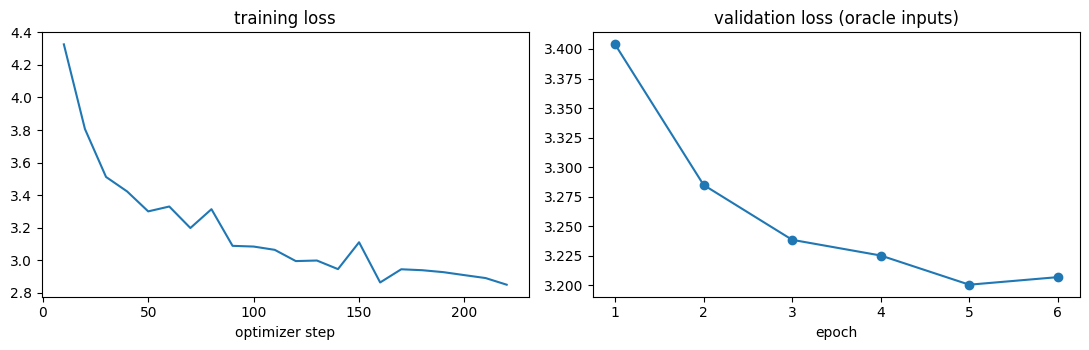

In [10]:
import matplotlib.pyplot as plt
lp = Path(OUT_DIR, "train_log.json")
if lp.exists():
    log = json.load(open(lp))
    tr = [(h["step"], h["loss"]) for h in log if "loss" in h]; ev = [(h["epoch"], h["eval_loss"]) for h in log if "eval_loss" in h]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    if tr: ax[0].plot(*zip(*tr)); ax[0].set_title("training loss"); ax[0].set_xlabel("optimizer step")
    if ev: ax[1].plot(*zip(*ev), marker="o"); ax[1].set_title("validation loss (oracle inputs)"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(Path(OUT_DIR, "figures", "led_loss.png"), dpi=130); plt.show()
else:
    print("no training log found (training was skipped in this session)")

## 5. Generate summaries from the Step 3+4 selections
Beam search (4 beams, no repeated trigrams, length penalty 2.0). Each summary is written to Drive as soon as it is produced; rerunning skips finished documents. Outputs shorter than 50 words fall back to the extractive summary.

In [11]:
tok = AutoTokenizer.from_pretrained(str(FINAL_DIR))
gen_model = AutoModelForSeq2SeqLM.from_pretrained(str(FINAL_DIR))
if HAS_GPU: gen_model = gen_model.half()
gen_model = gen_model.to(DEVICE).eval()

@torch.no_grad()
def generate(sources, beams=None):
    enc = tok(sources, max_length=MAX_INPUT_TOKENS, truncation=True, padding=True, return_tensors="pt").to(DEVICE)
    gam = torch.zeros_like(enc["input_ids"]); gam[:, 0] = 1                       # global attention on the first token
    out = gen_model.generate(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], global_attention_mask=gam,
                             num_beams=beams or NUM_BEAMS, no_repeat_ngram_size=NO_REPEAT_NGRAM, length_penalty=LENGTH_PENALTY,
                             max_length=GEN_MAX, min_length=min(GEN_MIN, GEN_MAX - 1), early_stopping=True)
    return [t.strip() for t in tok.batch_decode(out, skip_special_tokens=True)]

def generate_safe(sources):
    try:
        return generate(sources)
    except torch.cuda.OutOfMemoryError if HAS_GPU else RuntimeError:
        gc.collect(); torch.cuda.empty_cache() if HAS_GPU else None
        print("  out of memory: retrying one document at a time with 2 beams")
        return [generate([s], beams=2)[0] for s in sources]

rngv = random.Random(SEED)
todo = {}
for split in GEN_SPLITS:
    ids = sorted(SEL[split])
    if split == "validate": ids = rngv.sample(ids, min(N_VAL_GEN, len(ids)))
    todo[split] = ids

GEN = {s: {} for s in todo}; t0 = time.time()
for split, ids in todo.items():
    Path(OUT_DIR, "generations", split).mkdir(parents=True, exist_ok=True)
    jobs = []
    for d in ids:
        g = GR[(split, d)]; src, ents = make_source(g, SEL[split][d]["led_input_idx"])
        f = Path(OUT_DIR, "generations", split, d + ".txt")
        GEN[split][d] = dict(prefix_entities=ents, fallback=False, summary=None)
        if f.exists() and f.read_text(encoding="utf-8").strip(): GEN[split][d]["summary"] = f.read_text(encoding="utf-8")
        else: jobs.append((d, src, f))
    jobs.sort(key=lambda j: len(j[1]))                                              # similar lengths together = less padding
    for i in tqdm(range(0, len(jobs), GEN_BATCH), desc=f"generating {split}"):
        batch = jobs[i:i + GEN_BATCH]
        for (d, _, f), text in zip(batch, generate_safe([j[1] for j in batch])):
            if len(text.split()) < MIN_WORDS_OK:
                text = SEL[split][d]["extractive_text"]; GEN[split][d]["fallback"] = True
            GEN[split][d]["summary"] = text; f.write_text(text, encoding="utf-8")
print(f"generation finished in {(time.time() - t0) / 60:.1f} min | fallbacks to extractive:",
      {s: sum(v["fallback"] for v in GEN[s].values()) for s in GEN})
json.dump(GEN, open(Path(OUT_DIR, "generations.json"), "w"))

Loading weights:   0%|          | 0/296 [00:00<?, ?it/s]

generating test:   0%|          | 0/50 [00:00<?, ?it/s]

[transformers] Input ids are automatically padded from 560 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 929 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1343 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1347 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1432 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1525 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1573 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1535 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically

generating validate:   0%|          | 0/5 [00:00<?, ?it/s]

[transformers] Input ids are automatically padded from 1554 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1576 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1759 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 2132 to 3072 to be a multiple of `config.attention_window`: 1024


generation finished in 11.9 min | fallbacks to extractive: {'test': 0, 'validate': 0}


## 6. Evaluate: LED vs the extractive summary vs the LED input (official ROUGE on the same documents)
F-measures depend on length, so the table also shows mean words. The LED input row is what the generator had available (its ROUGE-recall caps what LED can reproduce).

In [12]:
from rouge_score import rouge_scorer
SC = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
def rouge(pairs):
    acc = {k: [] for k in ("rouge1", "rouge2", "rougeL")}
    for ref, hyp in pairs:
        s = SC.score(ref, hyp)
        for k in acc: acc[k].append(s[k].fmeasure)
    return {k: float(np.mean(v)) * 100 for k, v in acc.items()}

def adherence(summary, ents):
    if not ents: return np.nan
    t = f" {norm_entity(summary)} "
    return float(np.mean([f" {e} " in t for e in ents]))

rows = []
for split in GEN:
    ids = list(GEN[split]); refs = {d: GR[(split, d)]["reference"] for d in ids}
    systems = {"LED (abstractive)": {d: GEN[split][d]["summary"] for d in ids},
               "Extractive (Step 4)": {d: SEL[split][d]["extractive_text"] for d in ids},
               "LED input (selection fed to LED)": {d: SEL[split][d]["led_input_text"] for d in ids}}
    for name, hyp in systems.items():
        r = rouge([(refs[d], hyp[d]) for d in ids])
        rows.append({"Split": split, "System": name, "Docs": len(ids), "R-1": round(r["rouge1"], 2), "R-2": round(r["rouge2"], 2), "R-L": round(r["rougeL"], 2),
                     "Words": round(float(np.mean([len(hyp[d].split()) for d in ids])))})
    if USE_ENTITY_PREFIX:
        a = np.nanmean([adherence(GEN[split][d]["summary"], GEN[split][d]["prefix_entities"]) for d in ids])
        b = np.nanmean([adherence(refs[d], GEN[split][d]["prefix_entities"]) for d in ids])
        print(f"[{split}] entity control: {a:.0%} of the prefix entities appear in the LED summary (in the reference: {b:.0%})")
TABLE = pd.DataFrame(rows); TABLE.to_csv(Path(OUT_DIR, "results_table.csv"), index=False)
print(); print(TABLE.to_string(index=False))
print("\nTest rows use all test documents; validate rows use the", N_VAL_GEN, "sampled documents only (a sanity check, noisy).")

[test] entity control: 60% of the prefix entities appear in the LED summary (in the reference: 46%)
[validate] entity control: 68% of the prefix entities appear in the LED summary (in the reference: 41%)

   Split                           System  Docs   R-1   R-2   R-L  Words
    test                LED (abstractive)   100 57.01 31.93 28.01    648
    test              Extractive (Step 4)   100 57.33 35.90 32.74    936
    test LED input (selection fed to LED)   100 53.64 36.35 32.38   1357
validate                LED (abstractive)    10 54.73 30.02 27.16    662
validate              Extractive (Step 4)    10 51.73 29.41 28.76    851
validate LED input (selection fed to LED)    10 42.87 28.60 26.00   1342

Test rows use all test documents; validate rows use the 10 sampled documents only (a sanity check, noisy).


## 7. Look at a summary, and final checks

In [13]:
split = "test"; d = sorted(GEN[split])[0]; g = GR[(split, d)]
print(f"{d} | prefix entities: {GEN[split][d]['prefix_entities']}\n")
print("LED SUMMARY (first 900 characters):\n", GEN[split][d]["summary"][:900], "\n")
print("REFERENCE (first 900 characters):\n", g["reference"][:900])

n_files = {s: len(list(Path(OUT_DIR, "generations", s).glob("*.txt"))) for s in GEN}
print("\nsummary files written:", n_files, "| expected:", {s: len(v) for s, v in todo.items()})
assert all(n_files[s] >= len(todo[s]) for s in todo)
print("Step 6/7 read:  led/generations/<split>/<doc_id>.txt  and  led/generations.json")

test_1038 | prefix entities: ['section 3', 'state of madras', 'february 18 1955', 'section 13']

LED SUMMARY (first 900 characters):
 TRAIN - Summary 1038 The appellants are merchants dealing in cotton yarn. They obtained a license under section 5 of the Madras General Sales Tax Act (Act IX of 1939), hereinafter referred to as the 'Act '. This license exempted them from assessment to sales tax under section 3 of the Act on the sale of cotton yarn and on handloom cloth "subject to such restrictions and conditions as may be prescribed by and under the Act whether in the rules or in the licence itself". During the pendency of those proceedings the Deputy Commercial Tax Officer made assessments for the years 1943 44 and 1944 45, the tax for the former was Rs. 37,039 and for the latter Rs. 3,140. Both the suits were decreed by the Subordinate Judge and the decrees were confirmed on appeal by the District Judge of Salem. Two appeals were taken to the High Court by the State of Madras against